### Confusion Matrix: Measuring Accuracy and Precision

#### Keith R. Holdaway FGS

🚀 Starting Petrophysics AI Model Evaluation Demo
=== Generating Synthetic Petrophysics Data ===
Simulating well log data with 4 facies classes:
1. Sandstone (High porosity, clean)
2. Shale (Low porosity, high gamma ray)
3. Limestone (Moderate porosity, low gamma ray)
4. Dolomite (Variable porosity, high resistivity)

Data Summary:
Total samples: 1000
Training samples: 700
Testing samples: 300
Feature names: ['GR', 'RHOB', 'NPHI', 'RT', 'DT']
Facies distribution:
  Sandstone: 250 samples
  Shale: 250 samples
  Limestone: 250 samples
  Dolomite: 250 samples

=== Training Random Forest Model ===
Model training completed!
Training Accuracy: 1.000
Test Accuracy: 0.910

UNDERSTANDING THE CONFUSION MATRIX FOR PETROPHYSICISTS

🔍 What is a Confusion Matrix?
A confusion matrix is a table that shows how well your classification
model performs on test data where the true values are known.
It's like a 'quality control' check for your facies predictions!

📊 Matrix Components:
• Rows represent ACTUAL

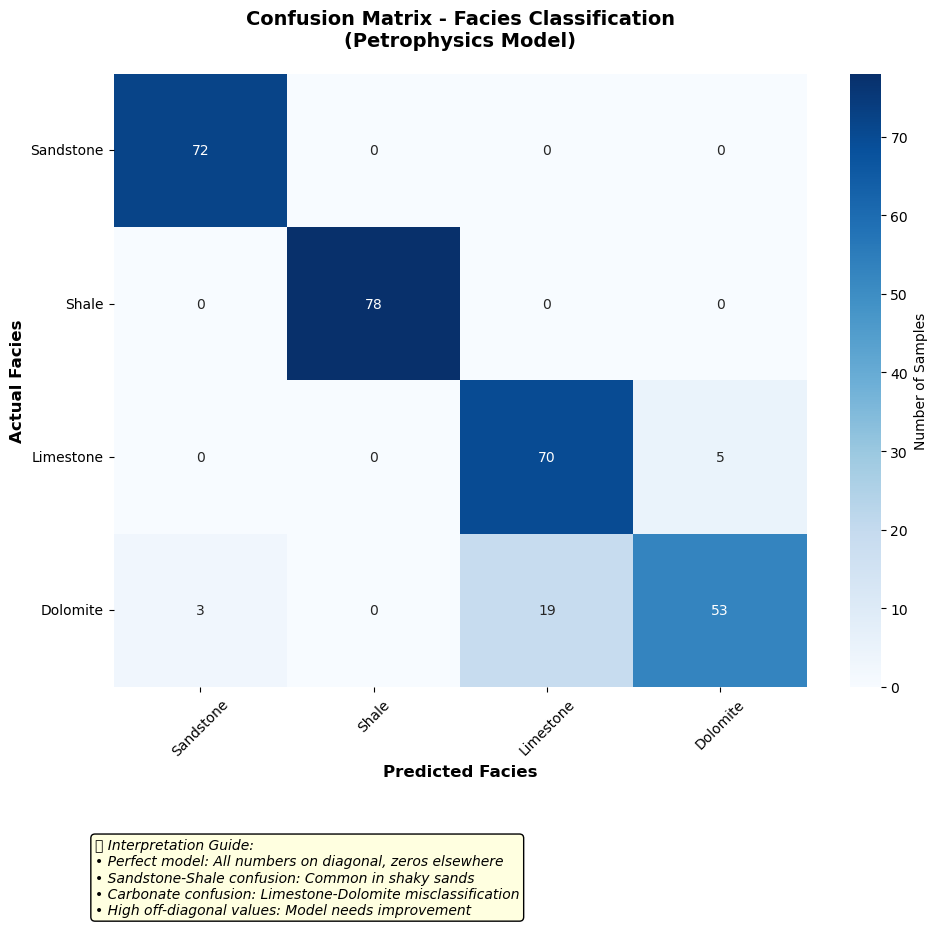


MODEL PERFORMANCE METRICS - PETROPHYSICS INTERPRETATION

📈 Overall Metrics:
Accuracy:  0.910 - Proportion of total correct predictions
Precision: 0.915 - How reliable positive predictions are
Recall:    0.910 - Ability to find all relevant cases
F1-Score:  0.908 - Balance between precision and recall

🎯 Petrophysics Significance:
• High Accuracy: Good overall facies prediction capability
• High Precision: When you predict 'Sandstone', it's likely correct
• High Recall: You're finding most of the actual sandstone intervals
• F1-Score: Best metric when class distribution is imbalanced

📊 Per-Facies Performance:
              precision    recall  f1-score   support

   Sandstone       0.96      1.00      0.98        72
       Shale       1.00      1.00      1.00        78
   Limestone       0.79      0.93      0.85        75
    Dolomite       0.91      0.71      0.80        75

    accuracy                           0.91       300
   macro avg       0.92      0.91      0.91       300
we

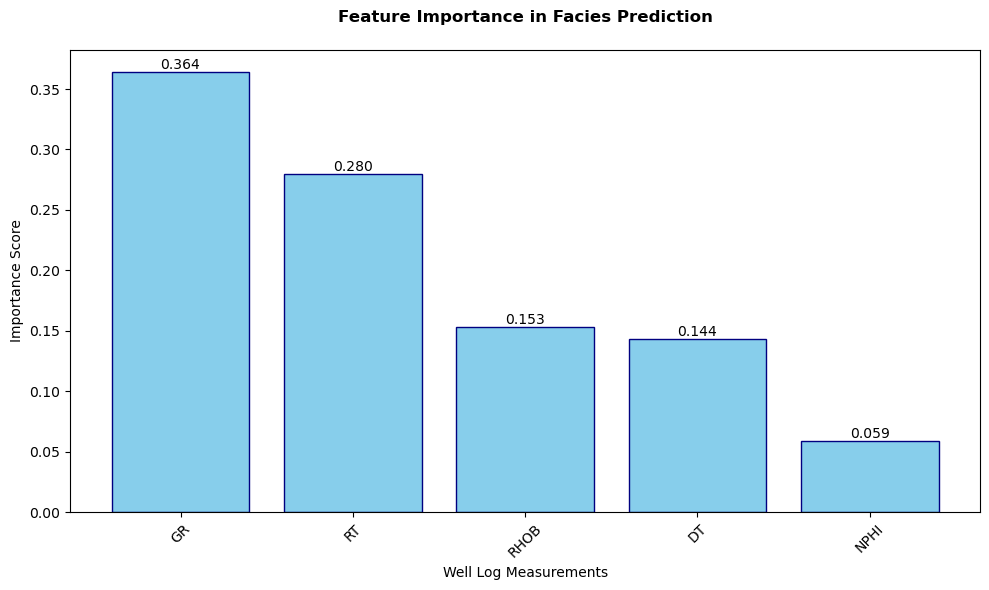


🔍 Petrophysics Insight:
Feature importance tells us which logs contribute most to facies discrimination:
1. GR: 0.364
2. RT: 0.280
3. RHOB: 0.153
4. DT: 0.144
5. NPHI: 0.059

💡 Interpretation:
High importance: Log provides unique information for facies separation
Low importance: Log may be redundant or noisy for this classification task

PREDICTION CONFIDENCE ANALYSIS

🔮 Model Confidence Examples:
High confidence prediction:
  Actual: Limestone, Predicted: Limestone
  Confidence: 1.000
  All probabilities: {'Sandstone': 0.0, 'Shale': 0.0, 'Limestone': 1.0, 'Dolomite': 0.0}

Low confidence prediction:
  Actual: Limestone, Predicted: Limestone
  Confidence: 0.420
  All probabilities: {'Sandstone': 0.28, 'Shale': 0.01, 'Limestone': 0.42, 'Dolomite': 0.29}

💡 Insight:
High confidence: Clear log signature, easy classification
Low confidence: Ambiguous log response, potential transition zone

PRACTICAL RECOMMENDATIONS FOR PETROPHYSICISTS
• 1. Start Simple: Use confusion matrix as your first

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.datasets import make_classification
import warnings
warnings.filterwarnings('ignore')

class PetrophysicsModelEvaluator:
    """
    A class to demonstrate model evaluation techniques for petrophysicists learning AI
    """
    
    def __init__(self):
        self.model = None
        self.X_test = None
        self.y_test = None
        self.predictions = None
        
    def generate_petrophysics_data(self):
        """
        Generate synthetic petrophysical data with balanced facies classes
        """
        print("=== Generating Synthetic Petrophysics Data ===")
        print("Simulating well log data with 4 facies classes:")
        print("1. Sandstone (High porosity, clean)")
        print("2. Shale (Low porosity, high gamma ray)")
        print("3. Limestone (Moderate porosity, low gamma ray)")
        print("4. Dolomite (Variable porosity, high resistivity)\n")
        
        # Generate balanced data for each facies
        np.random.seed(42)
        n_samples_per_class = 250  # Equal samples for each facies
        total_samples = n_samples_per_class * 4
        
        # Initialize lists to store data
        all_data = []
        facies_labels = []
        
        # 1. Sandstone - Clean, high porosity
        for i in range(n_samples_per_class):
            data_point = {
                'GR': np.random.normal(35, 10),      # Low Gamma Ray (clean)
                'RHOB': np.random.normal(2.2, 0.1),  # Low Density
                'NPHI': np.random.normal(0.25, 0.05), # High Neutron Porosity
                'RT': np.random.normal(15, 5),       # Moderate Resistivity
                'DT': np.random.normal(75, 10)       # Moderate Sonic
            }
            all_data.append(data_point)
            facies_labels.append(0)  # Sandstone
            
        # 2. Shale - High GR, high density
        for i in range(n_samples_per_class):
            data_point = {
                'GR': np.random.normal(120, 20),     # High Gamma Ray
                'RHOB': np.random.normal(2.6, 0.1),  # High Density
                'NPHI': np.random.normal(0.08, 0.03), # Low Neutron Porosity
                'RT': np.random.normal(5, 2),        # Low Resistivity
                'DT': np.random.normal(100, 15)      # High Sonic
            }
            all_data.append(data_point)
            facies_labels.append(1)  # Shale
            
        # 3. Limestone - Low GR, moderate porosity
        for i in range(n_samples_per_class):
            data_point = {
                'GR': np.random.normal(25, 8),       # Very Low Gamma Ray
                'RHOB': np.random.normal(2.5, 0.1),  # Moderate Density
                'NPHI': np.random.normal(0.15, 0.04), # Moderate Neutron
                'RT': np.random.normal(60, 20),      # High Resistivity
                'DT': np.random.normal(50, 8)        # Low Sonic
            }
            all_data.append(data_point)
            facies_labels.append(2)  # Limestone
            
        # 4. Dolomite - Variable, high resistivity
        for i in range(n_samples_per_class):
            data_point = {
                'GR': np.random.normal(45, 15),      # Moderate Gamma Ray
                'RHOB': np.random.normal(2.4, 0.2),  # Variable Density
                'NPHI': np.random.normal(0.12, 0.06), # Variable Neutron
                'RT': np.random.normal(80, 30),      # Very High Resistivity
                'DT': np.random.normal(55, 12)       # Low-Moderate Sonic
            }
            all_data.append(data_point)
            facies_labels.append(3)  # Dolomite
        
        # Convert to DataFrame
        self.X = pd.DataFrame(all_data)
        self.y = np.array(facies_labels)
        
        # Add some noise to make it more realistic
        for col in self.X.columns:
            self.X[col] += np.random.normal(0, 0.05, len(self.X))
        
        # Split the data - removed stratify to avoid the error
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            self.X, self.y, test_size=0.3, random_state=42
        )
        
        print("Data Summary:")
        print(f"Total samples: {len(self.X)}")
        print(f"Training samples: {len(self.X_train)}")
        print(f"Testing samples: {len(self.X_test)}")
        print(f"Feature names: {list(self.X.columns)}")
        
        # Show class distribution
        unique, counts = np.unique(self.y, return_counts=True)
        facies_names = ['Sandstone', 'Shale', 'Limestone', 'Dolomite']
        print("Facies distribution:")
        for name, count in zip(facies_names, counts):
            print(f"  {name}: {count} samples")
        
        return self.X_train, self.X_test, self.y_train, self.y_test
    
    def train_model(self):
        """Train a Random Forest classifier on the petrophysics data"""
        print("\n=== Training Random Forest Model ===")
        self.model = RandomForestClassifier(n_estimators=100, random_state=42)
        self.model.fit(self.X_train, self.y_train)
        self.predictions = self.model.predict(self.X_test)
        
        # Calculate training accuracy
        train_accuracy = self.model.score(self.X_train, self.y_train)
        test_accuracy = accuracy_score(self.y_test, self.predictions)
        
        print("Model training completed!")
        print(f"Training Accuracy: {train_accuracy:.3f}")
        print(f"Test Accuracy: {test_accuracy:.3f}")
        
    def explain_confusion_matrix(self):
        """
        Explain the confusion matrix in petrophysics terms
        """
        print("\n" + "="*70)
        print("UNDERSTANDING THE CONFUSION MATRIX FOR PETROPHYSICISTS")
        print("="*70)
        
        print("\n🔍 What is a Confusion Matrix?")
        print("A confusion matrix is a table that shows how well your classification")
        print("model performs on test data where the true values are known.")
        print("It's like a 'quality control' check for your facies predictions!\n")
        
        print("📊 Matrix Components:")
        print("• Rows represent ACTUAL facies classes")
        print("• Columns represent PREDICTED facies classes")
        print("• Diagonal elements (top-left to bottom-right) show CORRECT predictions")
        print("• Off-diagonal elements show MISCLASSIFICATIONS")
        
        print("\n🏗️ Practical Petrophysics Example:")
        print("If your model confuses Sandstone with Limestone:")
        print("→ This might indicate similar log responses in your dataset")
        print("→ Could suggest need for additional features (like PE curve)")
        print("→ Might reveal geological transitions in your formation")
        
    def plot_confusion_matrix(self):
        """Create and display a detailed confusion matrix"""
        cm = confusion_matrix(self.y_test, self.predictions)
        facies_names = ['Sandstone', 'Shale', 'Limestone', 'Dolomite']
        
        plt.figure(figsize=(10, 8))
        
        # Create heatmap
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                   xticklabels=facies_names, yticklabels=facies_names,
                   cbar_kws={'label': 'Number of Samples'})
        
        plt.title('Confusion Matrix - Facies Classification\n(Petrophysics Model)', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Predicted Facies', fontsize=12, fontweight='bold')
        plt.ylabel('Actual Facies', fontsize=12, fontweight='bold')
        plt.xticks(rotation=45)
        plt.yticks(rotation=0)
        
        # Add interpretation
        plt.figtext(0.1, -0.15, 
                   "💡 Interpretation Guide:\n"
                   "• Perfect model: All numbers on diagonal, zeros elsewhere\n"
                   "• Sandstone-Shale confusion: Common in shaky sands\n"
                   "• Carbonate confusion: Limestone-Dolomite misclassification\n"
                   "• High off-diagonal values: Model needs improvement", 
                   fontsize=10, style='italic', bbox=dict(boxstyle="round", facecolor='lightyellow'),
                   ha='left')
        
        plt.tight_layout()
        plt.show()
        
        return cm
    
    def calculate_metrics(self):
        """Calculate and display various accuracy and precision metrics"""
        print("\n" + "="*70)
        print("MODEL PERFORMANCE METRICS - PETROPHYSICS INTERPRETATION")
        print("="*70)
        
        # Calculate metrics
        accuracy = accuracy_score(self.y_test, self.predictions)
        precision = precision_score(self.y_test, self.predictions, average='weighted')
        recall = recall_score(self.y_test, self.predictions, average='weighted')
        f1 = f1_score(self.y_test, self.predictions, average='weighted')
        
        print(f"\n📈 Overall Metrics:")
        print(f"Accuracy:  {accuracy:.3f} - Proportion of total correct predictions")
        print(f"Precision: {precision:.3f} - How reliable positive predictions are")
        print(f"Recall:    {recall:.3f} - Ability to find all relevant cases")
        print(f"F1-Score:  {f1:.3f} - Balance between precision and recall")
        
        print("\n🎯 Petrophysics Significance:")
        print("• High Accuracy: Good overall facies prediction capability")
        print("• High Precision: When you predict 'Sandstone', it's likely correct")
        print("• High Recall: You're finding most of the actual sandstone intervals")
        print("• F1-Score: Best metric when class distribution is imbalanced")
        
        # Per-class metrics
        print("\n📊 Per-Facies Performance:")
        class_report = classification_report(self.y_test, self.predictions, 
                                           target_names=['Sandstone', 'Shale', 'Limestone', 'Dolomite'])
        print(class_report)
    
    def feature_importance_analysis(self):
        """Show which well log measurements are most important for predictions"""
        print("\n" + "="*70)
        print("FEATURE IMPORTANCE ANALYSIS")
        print("="*70)
        
        if self.model is not None:
            importance = self.model.feature_importances_
            features = self.X.columns
            
            # Create feature importance plot
            plt.figure(figsize=(10, 6))
            indices = np.argsort(importance)[::-1]
            
            bars = plt.bar(range(len(features)), importance[indices], color='skyblue', edgecolor='navy')
            plt.xticks(range(len(features)), [features[i] for i in indices], rotation=45)
            plt.title('Feature Importance in Facies Prediction', fontweight='bold', pad=20)
            plt.ylabel('Importance Score')
            plt.xlabel('Well Log Measurements')
            
            # Add value labels on bars
            for bar in bars:
                height = bar.get_height()
                plt.text(bar.get_x() + bar.get_width()/2., height,
                        f'{height:.3f}', ha='center', va='bottom')
            
            plt.tight_layout()
            plt.show()
            
            print("\n🔍 Petrophysics Insight:")
            print("Feature importance tells us which logs contribute most to facies discrimination:")
            for i, idx in enumerate(indices):
                print(f"{i+1}. {features[idx]}: {importance[idx]:.3f}")
            
            print("\n💡 Interpretation:")
            print("High importance: Log provides unique information for facies separation")
            print("Low importance: Log may be redundant or noisy for this classification task")
    
    def practical_recommendations(self):
        """Provide practical recommendations for petrophysicists"""
        print("\n" + "="*70)
        print("PRACTICAL RECOMMENDATIONS FOR PETROPHYSICISTS")
        print("="*70)
        
        recommendations = [
            "1. Start Simple: Use confusion matrix as your first diagnostic tool",
            "2. Focus on Business Impact: Some misclassifications matter more than others",
            "3. Cross-Validate: Always test on multiple wells or different formations",
            "4. Feature Engineering: Create derived parameters (Vshale, PhiE, Sw) as features",
            "5. Handle Imbalance: Some facies might be rare - use appropriate sampling",
            "6. Domain Knowledge: Use geological constraints to improve predictions",
            "7. Quality Control: Compare AI predictions with core data when available",
            "8. Iterate: Model improvement is an iterative process"
        ]
        
        for rec in recommendations:
            print(f"• {rec}")
    
    def demonstrate_prediction_confidence(self):
        """Show prediction probabilities to demonstrate model confidence"""
        print("\n" + "="*70)
        print("PREDICTION CONFIDENCE ANALYSIS")
        print("="*70)
        
        if self.model is not None:
            # Get prediction probabilities
            probabilities = self.model.predict_proba(self.X_test)
            facies_names = ['Sandstone', 'Shale', 'Limestone', 'Dolomite']
            
            print("\n🔮 Model Confidence Examples:")
            print("High confidence prediction:")
            high_conf_idx = np.argmax(np.max(probabilities, axis=1))
            actual_facies = facies_names[self.y_test[high_conf_idx]]
            pred_facies = facies_names[self.predictions[high_conf_idx]]
            conf = np.max(probabilities[high_conf_idx])
            
            print(f"  Actual: {actual_facies}, Predicted: {pred_facies}")
            print(f"  Confidence: {conf:.3f}")
            print(f"  All probabilities: {dict(zip(facies_names, probabilities[high_conf_idx]))}")
            
            print("\nLow confidence prediction:")
            low_conf_idx = np.argmin(np.max(probabilities, axis=1))
            actual_facies = facies_names[self.y_test[low_conf_idx]]
            pred_facies = facies_names[self.predictions[low_conf_idx]]
            conf = np.max(probabilities[low_conf_idx])
            
            print(f"  Actual: {actual_facies}, Predicted: {pred_facies}")
            print(f"  Confidence: {conf:.3f}")
            print(f"  All probabilities: {dict(zip(facies_names, probabilities[low_conf_idx]))}")
            
            print("\n💡 Insight:")
            print("High confidence: Clear log signature, easy classification")
            print("Low confidence: Ambiguous log response, potential transition zone")
    
    def run_complete_analysis(self):
        """Run the complete analysis pipeline"""
        print("🚀 Starting Petrophysics AI Model Evaluation Demo")
        print("="*70)
        
        # Generate and explore data
        self.generate_petrophysics_data()
        
        # Train model
        self.train_model()
        
        # Confusion matrix explanation and visualization
        self.explain_confusion_matrix()
        cm = self.plot_confusion_matrix()
        
        # Calculate and interpret metrics
        self.calculate_metrics()
        
        # Feature importance
        self.feature_importance_analysis()
        
        # Prediction confidence
        self.demonstrate_prediction_confidence()
        
        # Practical recommendations
        self.practical_recommendations()
        
        print("\n" + "="*70)
        print("🎉 Analysis Complete! Key Takeaways:")
        print("• Confusion matrix helps identify specific misclassification patterns")
        print("• Multiple metrics provide different perspectives on model performance")
        print("• Feature importance guides log selection and acquisition planning")
        print("• Always combine AI results with petrophysical expertise")
        print("="*70)

# Run the demonstration
if __name__ == "__main__":
    # Create evaluator instance
    evaluator = PetrophysicsModelEvaluator()
    
    # Run complete analysis
    evaluator.run_complete_analysis()
    
    # Additional example: Real-time prediction simulation
    print("\n" + "="*70)
    print("🔮 REAL-TIME PREDICTION SIMULATION")
    print("="*70)
    
    # Simulate new data points for different facies
    test_cases = [
        {
            'name': 'Clean Sandstone',
            'data': {'GR': 30, 'RHOB': 2.15, 'NPHI': 0.28, 'RT': 12, 'DT': 70},
            'expected': 'Sandstone'
        },
        {
            'name': 'Shale',
            'data': {'GR': 135, 'RHOB': 2.65, 'NPHI': 0.06, 'RT': 4, 'DT': 110},
            'expected': 'Shale'
        },
        {
            'name': 'Limestone',
            'data': {'GR': 20, 'RHOB': 2.55, 'NPHI': 0.14, 'RT': 75, 'DT': 45},
            'expected': 'Limestone'
        }
    ]
    
    facies_names = ['Sandstone', 'Shale', 'Limestone', 'Dolomite']
    
    for case in test_cases:
        new_measurement = pd.DataFrame([case['data']])
        prediction = evaluator.model.predict(new_measurement)[0]
        probabilities = evaluator.model.predict_proba(new_measurement)[0]
        
        print(f"\n📊 Test Case: {case['name']}")
        print(f"Log Measurements: GR={case['data']['GR']} API, RHOB={case['data']['RHOB']} g/cc")
        print(f"                 NPHI={case['data']['NPHI']}, RT={case['data']['RT']} ohm-m, DT={case['data']['DT']} us/ft")
        print(f"🤖 Predicted Facies: {facies_names[prediction]}")
        print(f"📈 Confidence: {probabilities[prediction]:.3f}")
        print(f"✅ Expected: {case['expected']}")
        print(f"All probabilities: {dict(zip(facies_names, probabilities))}")